# 02 · Reference models: degree-preserving swap randomisations

**Purpose.** Estimate how often each of the 595 pairs of tactics would appear together inside the same action if tactics were combined at random, given (i) how many tactics each action lists and (ii) how often each tactic is used in a given stratum. The gap between observed and expected co-occurrence is the combinatorial structure studied in the paper.

**Reference models** (specified in `../config/analysis.json`):

| Name | Swaps allowed between occupied fields of different actions… | Preserves |
|---|---|---|
| `N1` | in the same calendar month | tactics per action; monthly frequency of each tactic |
| `N2` (primary) | in the same year × territorial block × P20a field × field position | occupied fields per action; field-specific frequency of each tactic in each context cell |
| `N2_clean` | as N2, after removing codes 2 and 10 and actions with residual, invalid or six occupied fields | as N2 |
| `N2_allmedia` | as N2, all media | as N2 |
| `N2_order` | as N2, rejecting swaps that change whether an action's list is in ascending numeric order | as N2 + order status |
| `N1_k2` | as N1, only actions with exactly two tactics | as N1 |

A swap exchanges the codes of two occupied fields that belong to different actions in the same stratum, and is rejected if it would repeat a tactic inside an action. The proposal is symmetric and each swap is its own inverse, so the chain's stationary distribution is uniform over the reachable configurations with the stated margins. N1 and N2 are complementary, not nested: N2 does not preserve monthly margins.

**MCMC.** 999 samples per model in four chains (250, 250, 250, 249), burn-in 20 × (number of occupied fields) proposals and 10 × between samples. Seeds `20261103 + 1000·model + 101·chain`.

**Sampler verification.** Small fixtures check the constraints, pair counts and deterministic seeds. An enumerable example checks the distribution of visited configurations. A separate C++ implementation provides an independent comparison of expected counts.

**Local intermediates.** Aggregates in `../results/aggregates/` (per-year replicate counts; per-month observed and expected counts). Day-level observed and expected counts go to `../data_local/` and stay local.

In [1]:
import os

for k in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS"]:
    os.environ.setdefault(k, "2")
import hashlib, json, time, itertools, subprocess, tempfile, ctypes, shutil
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import numba
from numba import njit
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PROTEST_ROOT", Path.cwd())).expanduser().resolve()
if not (ROOT / "config" / "analysis.json").is_file():
    ROOT = ROOT.parent
if not (ROOT / "config" / "analysis.json").is_file():
    raise FileNotFoundError(
        "Open this notebook from the repository root or its notebooks folder, or set PROTEST_ROOT."
    )
CFG = json.loads((ROOT / "config" / "analysis.json").read_text())
TAB = ROOT / "results" / "tables"
AGG = ROOT / "results" / "aggregates"
LOCAL = ROOT / "data_local"
AGG.mkdir(parents=True, exist_ok=True)
DIAG = ROOT / "results" / "diagnostics"
DIAG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)


def display_figure(fig, name):
    """Show and export the same diagnostic figure."""
    display(fig)
    fig.savefig(DIAG / f"{name}.pdf", bbox_inches="tight")
    plt.close(fig)


def display_and_save_table(df, name, index=False, float_format="%.4f"):
    display(df)
    df.to_csv(TAB / f"{name}.csv", index=index)
    df.to_latex(
        TAB / f"{name}.tex", index=index, escape=True, float_format=lambda x: float_format % x
    )
    return df


actions = pd.read_parquet(LOCAL / "actions.parquet")
meta01 = json.loads((ROOT / "results" / "01_reconstruction_meta.json").read_text())
h = hashlib.sha256((LOCAL / "actions.parquet").read_bytes()).hexdigest()
assert h == meta01["actions_parquet_sha256"]
PAIRS = np.array(
    list(itertools.combinations(range(1, 36), 2)), dtype=np.int64
)  # 595 pairs, code_i < code_j
PM = np.full((36, 36), -1, dtype=np.int64)
for idx, (i, j) in enumerate(PAIRS):
    PM[i, j] = PM[j, i] = idx
YEARS = np.arange(2008, 2025)
MONTHS = pd.period_range("2008-01", "2024-12", freq="M").astype(str).to_numpy()
print(
    "numba",
    numba.__version__,
    "| actions (all media, eligible):",
    len(actions),
    "| pairs:",
    len(PAIRS),
    "| months:",
    len(MONTHS),
)


numba 0.68.1 | actions (all media, eligible): 34118 | pairs: 595 | months: 204


## 1. Swap kernel

`swap_step` is the only place where the randomisation happens; the chain runner and the uniformity test both call it.

In [2]:
@njit(cache=False)
def is_ascending(A, r):
    prev = 0
    for k in range(A.shape[1]):
        v = A[r, k]
        if v > 0:
            if v <= prev:
                return False
            prev = v
    return True


@njit(cache=False)
def swap_step(A, er, es, gid, ptr, ordered):
    """One proposal. Returns 1 if accepted. A[r, slot] holds a code (0 = empty field)."""
    ne = er.shape[0]
    e = np.random.randint(0, ne)
    g = gid[e]
    f = ptr[g] + np.random.randint(0, ptr[g + 1] - ptr[g])
    r = er[e]
    s = er[f]
    p = es[e]
    q = es[f]
    v = A[r, p]
    w = A[s, q]
    if r == s or v == w:
        return 0
    for k in range(A.shape[1]):
        if A[r, k] == w or A[s, k] == v:
            return 0  # would repeat a tactic inside an action
    if ordered:
        ar = is_ascending(A, r)
        a_s = is_ascending(A, s)
    A[r, p] = w
    A[s, q] = v
    if ordered:
        if is_ascending(A, r) != ar or is_ascending(A, s) != a_s:
            A[r, p] = v
            A[s, q] = w
            return 0
    return 1


@njit(cache=False)
def run_chain(
    A, er, es, gid, ptr, ordered, reps, burn_mult, thin_mult, seed, year_idx, n_years, PM
):
    """Returns per-sample pair counts by year (reps x n_years x 595), the per-action sum of pair
    indicators over samples (n_actions x 595) and diagnostics [proposals, accepted]."""
    np.random.seed(seed)
    n = A.shape[0]
    ne = er.shape[0]
    counts = np.zeros((reps, n_years, 595), dtype=np.int32)
    acc = np.zeros((n, 595), dtype=np.int32)
    proposals = 0
    accepted = 0
    for b in range(-1, reps):
        steps = ne * (burn_mult if b < 0 else thin_mult)
        for t in range(steps):
            proposals += 1
            accepted += swap_step(A, er, es, gid, ptr, ordered)
        if b >= 0:
            for r in range(n):
                y = year_idx[r]
                for p in range(A.shape[1]):
                    v = A[r, p]
                    if v == 0:
                        continue
                    for q in range(p + 1, A.shape[1]):
                        w = A[r, q]
                        if w == 0:
                            continue
                        hh = PM[v, w]
                        counts[b, y, hh] += 1
                        acc[r, hh] += 1
    return counts, acc, np.array([proposals, accepted], dtype=np.int64)


def build_cells(A, keys):
    """Edges = occupied fields, grouped by stratum key; returns arrays for the kernel."""
    rows, slots = np.nonzero(A)
    k = np.array([keys[r][s] for r, s in zip(rows, slots)])
    codes, uniq = pd.factorize(k, sort=True)
    order = np.argsort(codes, kind="stable")
    er = rows[order].astype(np.int64)
    es = slots[order].astype(np.int64)
    gid = codes[order].astype(np.int64)
    ptr = np.r_[0, np.cumsum(np.bincount(gid, minlength=len(uniq)))].astype(np.int64)
    return er, es, gid, ptr


def cell_histogram(A, er, es, gid, ncell):
    return np.bincount(gid * 36 + A[er, es], minlength=ncell * 36).reshape(ncell, 36)


def observed_pairs(A):
    """Independent pair count per action via the binary incidence matrix (numpy, no loops over fields)."""
    B = np.zeros((A.shape[0], 36), dtype=np.int8)
    rr = np.repeat(np.arange(A.shape[0]), A.shape[1])
    B[rr, A.ravel()] = 1
    B[:, 0] = 0
    return B[:, PAIRS[:, 0]] & B[:, PAIRS[:, 1]]  # n x 595 indicators


print("kernel compiled lazily on first call")


kernel compiled lazily on first call


## 2. Kernel tests

**(a) Invariants and an independent count.** On a small fixture, for each combination of stratification (none / by field) and order constraint, the kernel must preserve the occupied-field mask, the code histogram of every stratum, the absence of repeated tactics, and (when constrained) each action's order status. Its pair counts must equal a count from the binary incidence matrix, and the same seed must give the same result.

In [3]:
fixture = np.array(
    [
        [1, 2, 0, 0, 0, 0],
        [1, 3, 4, 0, 0, 0],
        [4, 2, 0, 0, 0, 0],
        [3, 1, 0, 0, 0, 0],
        [5, 4, 1, 0, 0, 0],
        [2, 5, 0, 0, 0, 0],
        [4, 1, 0, 0, 0, 0],
        [2, 3, 5, 0, 0, 0],
    ],
    dtype=np.int64,
)
fy = np.array([0, 0, 0, 0, 1, 1, 1, 1], dtype=np.int64)
tests = []
for by_slot in (False, True):
    keys = [[(f"s{s}" if by_slot else "all") for s in range(6)] for _ in range(len(fixture))]
    er, es, gid, ptr = build_cells(fixture, keys)
    h0 = cell_histogram(fixture, er, es, gid, len(ptr) - 1)
    for ordered in (False, True):
        runs = []
        for rep in range(2):
            A = fixture.copy()
            counts, acc, diag = run_chain(A, er, es, gid, ptr, ordered, 3, 20, 10, 123, fy, 2, PM)
            assert np.array_equal(A > 0, fixture > 0)
            assert np.array_equal(cell_histogram(A, er, es, gid, len(ptr) - 1), h0)
            assert all(len(set(r[r > 0])) == (r > 0).sum() for r in A)
            if ordered:
                assert all(is_ascending(A, i) == is_ascending(fixture, i) for i in range(len(A)))
            ob = observed_pairs(A)
            assert np.array_equal(counts[-1].sum(0), ob.sum(0))
            assert np.array_equal(counts[-1, 1], ob[fy == 1].sum(0))
            runs.append((A, counts, acc))
        assert all(np.array_equal(x, y) for x, y in zip(runs[0], runs[1]))
        tests.append(
            {
                "by_slot": by_slot,
                "ordered": ordered,
                "invariants": True,
                "independent_count": True,
                "deterministic_seed": True,
                "acceptance": diag[1] / diag[0],
            }
        )
pd.DataFrame(tests)


,by_slot,ordered,invariants,independent_count,deterministic_seed,acceptance
0,False,False,True,True,True,0.329474
1,False,True,True,True,True,0.174737
2,True,False,True,True,True,0.277895
3,True,True,True,True,True,0.202105


**(b) Exact uniformity.** For a fixture small enough to enumerate every configuration that respects the margins, the chain's visit frequencies must be uniform over the configurations it can reach, and it must reach all of them. We record the state after every 50 proposals over 400,000 recorded states and compare with a χ² test.

In [4]:
@njit(cache=False)
def trace_states(A, er, es, gid, ptr, ordered, n_states, thin, seed, base):
    np.random.seed(seed)
    out = np.zeros(n_states, dtype=np.int64)
    for t in range(n_states):
        for _ in range(thin):
            swap_step(A, er, es, gid, ptr, ordered)
        code = 0
        for i in range(er.shape[0]):
            code = code * base + A[er[i], es[i]]
        out[t] = code
    return out


def enumerate_valid(fixture, er, es, gid, ordered):
    """All assignments of each stratum's multiset of codes to that stratum's fields, with no repeated
    tactic within an action (and same order status if ordered)."""
    cells = sorted(set(gid.tolist()))
    per_cell = []
    for c in cells:
        idx = np.where(gid == c)[0]
        vals = fixture[er[idx], es[idx]]
        per_cell.append((idx, sorted(set(itertools.permutations(vals.tolist())))))
    states = []
    for combo in itertools.product(*[p for _, p in per_cell]):
        A = fixture.copy()
        for (idx, _), perm in zip(per_cell, combo):
            A[er[idx], es[idx]] = perm
        if any(len(set(r[r > 0])) != (r > 0).sum() for r in A):
            continue
        if ordered and any(is_ascending(A, i) != is_ascending(fixture, i) for i in range(len(A))):
            continue
        code = 0
        for i in range(len(er)):
            code = code * 36 + A[er[i], es[i]]
        states.append(code)
    return np.array(sorted(set(states)))


from scipy.stats import chisquare

small = np.array(
    [
        [1, 2, 0, 0, 0, 0],
        [2, 3, 0, 0, 0, 0],
        [3, 1, 4, 0, 0, 0],
        [4, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0],
    ],
    dtype=np.int64,
)
uni = []
for by_slot in (False, True):
    for ordered in (False, True):
        keys = [[(f"s{s}" if by_slot else "all") for s in range(6)] for _ in range(len(small))]
        er, es, gid, ptr = build_cells(small, keys)
        valid = enumerate_valid(small, er, es, gid, ordered)
        tr = trace_states(small.copy(), er, es, gid, ptr, ordered, 400_000, 50, 7, 36)
        vals, cnt = np.unique(tr, return_counts=True)
        reached = np.isin(valid, vals)
        assert np.all(np.isin(vals, valid)), "chain visited an invalid state"
        full = np.array([cnt[vals == v][0] if v in set(vals) else 0 for v in valid])
        uni.append(
            {
                "by_slot": by_slot,
                "ordered": ordered,
                "valid_states": len(valid),
                "reached": int(reached.sum()),
                "chi2_p_uniform": chisquare(full).pvalue if len(valid) > 1 else np.nan,
                "min_over_max_visits": full.min() / full.max(),
            }
        )
uniformity = pd.DataFrame(uni)
display_and_save_table(uniformity, "kernel_uniformity_test")
uniformity


,by_slot,ordered,valid_states,reached,chi2_p_uniform,min_over_max_visits
0,False,False,2880,2880,0.558924,0.563536
1,False,True,600,600,0.464773,0.768407
2,True,False,116,116,0.716771,0.914437
3,True,True,12,12,0.677288,0.983272


,by_slot,ordered,valid_states,reached,chi2_p_uniform,min_over_max_visits
0,False,False,2880,2880,0.558924,0.563536
1,False,True,600,600,0.464773,0.768407
2,True,False,116,116,0.716771,0.914437
3,True,True,12,12,0.677288,0.983272


## 3. Build each specification and run the chains

In [5]:
def spec_sample(name):
    a = actions.copy()
    if name in ("N1", "N2", "N2_order", "N1_k2", "N2_clean"):
        a = a[a.pb.eq(0)]
    if name == "N1_k2":
        a = a[a.n_unique.eq(2)]
    A = a[[f"s{j}" for j in range(1, 7)]].to_numpy().astype(np.int64)
    if name == "N2_clean":
        keep = (a.n_other.eq(0) & a.n_invalid.eq(0) & a.n_nonmissing.lt(6)).to_numpy()
        a = a[keep]
        A = A[keep]
        A[np.isin(A, [2, 10])] = 0
        keep2 = (A > 0).sum(1) > 0
        a = a[keep2]
        A = A[keep2]
    a = a.reset_index(drop=True)
    if name.startswith("N1"):
        keys = [[m] * 6 for m in a.month]
    else:
        ctx = (a.year.astype(str) + "|" + a.block + "|" + a.p20_broad).tolist()
        keys = [[f"{c}|{s}" for s in range(6)] for c in ctx]
    return a, A, keys


SPECS = ["N1", "N2", "N2_clean", "N2_allmedia", "N2_order", "N1_k2"]
SEED0 = CFG["mcmc"]["seed"]
CHAIN_SIZES = CFG["mcmc"]["samples_per_chain"]
BURN = CFG["mcmc"]["burn_in_per_field"]
THIN = CFG["mcmc"]["thinning_per_field"]
assert sum(CHAIN_SIZES) == CFG["mcmc"]["samples_per_spec"]
diag_rows = []
spec_rows = []
t_all = time.time()
for si, name in enumerate(SPECS):
    t0 = time.time()
    a, A0, keys = spec_sample(name)
    er, es, gid, ptr = build_cells(A0, keys)
    ncell = len(ptr) - 1
    h0 = cell_histogram(A0, er, es, gid, ncell)
    year_idx = (a.year.to_numpy() - 2008).astype(np.int64)
    ordered = name == "N2_order"
    obs_ind = observed_pairs(A0)
    asc0 = np.array([is_ascending(A0, i) for i in range(len(A0))])
    # strata where no swap can ever change anything: a single action or a single distinct code
    sizes = np.diff(ptr)
    fixed = np.array(
        [
            len(set(er[ptr[g] : ptr[g + 1]].tolist())) <= 1
            or len(set(A0[er[ptr[g] : ptr[g + 1]], es[ptr[g] : ptr[g + 1]]].tolist())) <= 1
            for g in range(ncell)
        ]
    )
    counts_all = []
    acc_sum = np.zeros((len(a), 595), dtype=np.int64)
    per_chain_month = []
    month_idx = pd.Index(MONTHS).get_indexer(a.month)
    for ch, nr in enumerate(CHAIN_SIZES):
        A = A0.copy()
        seed = SEED0 + 1000 * si + 101 * ch
        counts, acc, d = run_chain(
            A, er, es, gid, ptr, ordered, nr, BURN, THIN, seed, year_idx, len(YEARS), PM
        )
        assert np.array_equal(A > 0, A0 > 0) and np.array_equal(
            cell_histogram(A, er, es, gid, ncell), h0
        )
        assert all(len(set(r[r > 0])) == (r > 0).sum() for r in A)
        if ordered:
            assert np.array_equal(np.array([is_ascending(A, i) for i in range(len(A))]), asc0)
        multi = (A0 > 0).sum(1) >= 2
        diag_rows.append(
            {
                "spec": name,
                "chain": ch,
                "seed": seed,
                "samples": nr,
                "proposals": int(d[0]),
                "accepted": int(d[1]),
                "acceptance": d[1] / d[0],
                "final_changed_field_fraction": float((A != A0)[A0 > 0].mean()),
                "final_changed_order_fraction_multi": float(
                    np.mean([is_ascending(A, i) != asc0[i] for i in np.where(multi)[0]])
                ),
            }
        )
        counts_all.append(counts)
        acc_sum += acc
        per_chain_month.append(
            np.stack(
                [
                    np.bincount(month_idx, weights=acc[:, hh] / nr, minlength=len(MONTHS))
                    for hh in range(595)
                ],
                1,
            ).astype(np.float32)
        )
    counts_all = np.concatenate(counts_all)  # 999 x 17 x 595
    R = counts_all.shape[0]
    e_action = acc_sum / R  # expected pair indicators per action
    obs_year = np.stack([obs_ind[year_idx == y].sum(0) for y in range(len(YEARS))])
    assert np.allclose(
        counts_all.mean(0), np.stack([e_action[year_idx == y].sum(0) for y in range(len(YEARS))])
    )
    # Month-level caches and local-only day-level caches for downstream notebooks.
    obs_month = np.stack(
        [
            np.bincount(month_idx, weights=obs_ind[:, hh], minlength=len(MONTHS))
            for hh in range(595)
        ],
        1,
    ).astype(np.int32)
    exp_month = np.stack(
        [
            np.bincount(month_idx, weights=e_action[:, hh], minlength=len(MONTHS))
            for hh in range(595)
        ],
        1,
    )
    days, day_idx = np.unique(a.day.to_numpy(), return_inverse=True)
    obs_day = np.stack(
        [np.bincount(day_idx, weights=obs_ind[:, hh], minlength=len(days)) for hh in range(595)], 1
    ).astype(np.int32)
    exp_day = np.stack(
        [np.bincount(day_idx, weights=e_action[:, hh], minlength=len(days)) for hh in range(595)], 1
    ).astype(np.float32)
    n_actions_month = np.bincount(month_idx, minlength=len(MONTHS))
    n_actions_day = np.bincount(day_idx, minlength=len(days))
    np.savez_compressed(
        AGG / f"null_{name}.npz",
        counts=counts_all,
        observed_year=obs_year,
        years=YEARS,
        chain=np.repeat(np.arange(len(CHAIN_SIZES)), CHAIN_SIZES),
    )
    np.savez_compressed(
        AGG / f"month_OE_{name}.npz",
        observed=obs_month,
        expected=exp_month.astype(np.float32),
        expected_by_chain=np.stack(per_chain_month),
        months=MONTHS,
        n_actions=n_actions_month,
    )
    np.savez_compressed(
        LOCAL / f"day_OE_{name}.npz",
        observed=obs_day,
        expected=exp_day,
        days=days,
        n_actions=n_actions_day,
    )
    spec_rows.append(
        {
            "spec": name,
            "actions": len(a),
            "multi_tactic_actions": int(((A0 > 0).sum(1) >= 2).sum()),
            "occupied_fields": len(er),
            "strata": ncell,
            "fields_in_fixed_strata": float(np.repeat(fixed, sizes).mean()),
            "observed_pairs_total": int(obs_ind.sum()),
            "seconds": round(time.time() - t0, 1),
        }
    )
    print(name, spec_rows[-1], flush=True)
print("total seconds", round(time.time() - t_all, 1))


N1 {'spec': 'N1', 'actions': 27488, 'multi_tactic_actions': 13405, 'occupied_fields': 47097, 'strata': 204, 'fields_in_fixed_strata': 0.0, 'observed_pairs_total': 28256, 'seconds': 48.3}


N2 {'spec': 'N2', 'actions': 27488, 'multi_tactic_actions': 13405, 'occupied_fields': 47097, 'strata': 1536, 'fields_in_fixed_strata': 0.008960231012591035, 'observed_pairs_total': 28256, 'seconds': 53.3}


N2_clean {'spec': 'N2_clean', 'actions': 23559, 'multi_tactic_actions': 6666, 'occupied_fields': 32707, 'strata': 1362, 'fields_in_fixed_strata': 0.011801754975999022, 'observed_pairs_total': 12310, 'seconds': 31.5}


N2_allmedia {'spec': 'N2_allmedia', 'actions': 34118, 'multi_tactic_actions': 15863, 'occupied_fields': 56964, 'strata': 1575, 'fields_in_fixed_strata': 0.007039533740608103, 'observed_pairs_total': 32443, 'seconds': 58.2}


N2_order {'spec': 'N2_order', 'actions': 27488, 'multi_tactic_actions': 13405, 'occupied_fields': 47097, 'strata': 1536, 'fields_in_fixed_strata': 0.008960231012591035, 'observed_pairs_total': 28256, 'seconds': 57.1}


N1_k2 {'spec': 'N1_k2', 'actions': 8981, 'multi_tactic_actions': 8981, 'occupied_fields': 17962, 'strata': 204, 'fields_in_fixed_strata': 0.0, 'observed_pairs_total': 8981, 'seconds': 16.5}


total seconds 264.8


## 4. Chain diagnostics

For every pair whose reference count varies, we compute split-R̂ across the four chains (Gelman et al.), a lag-1 autocorrelation of successive samples, and an effective sample size from the within-chain autocorrelation (initial positive sequence). The acceptance rate and the share of fields changed by the end of each chain show how much of the constrained state space the sampler explores.

In [6]:
def split_rhat(x):  # x: chains x draws
    half = x.shape[1] // 2
    s = np.concatenate([x[:, :half], x[:, half : 2 * half]])
    m, n = s.shape
    W = s.var(axis=1, ddof=1).mean()
    B = n * s.mean(axis=1).var(ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W) if W > 0 else np.nan


def ess(x):  # x: chains x draws
    m, n = x.shape
    xc = x - x.mean(axis=1, keepdims=True)
    var = xc.var(axis=1).mean()
    if var == 0:
        return np.nan
    rho_sum = 0.0
    for lag in range(1, n // 2):
        r = np.mean([np.dot(c[:-lag], c[lag:]) / (n * c.var()) for c in xc if c.var() > 0])
        if r < 0.05:
            break
        rho_sum += r
    return m * n / (1 + 2 * rho_sum)


rows = []
for name in SPECS:
    z = np.load(AGG / f"null_{name}.npz")
    tot = z["counts"].sum(1).astype(float)  # 999 x 595
    ch = z["chain"]
    m = min(CHAIN_SIZES)
    X = np.stack([tot[ch == c][:m] for c in range(len(CHAIN_SIZES))])  # chains x draws x pairs
    var_pairs = np.where(tot.std(0) > 0)[0]
    rh = np.array([split_rhat(X[:, :, hh]) for hh in var_pairs])
    # A rare pair can have a constant lagged segment despite varying over the full chain.
    # Its lag correlation is undefined (NaN), and nanquantile excludes it below.
    with np.errstate(invalid="ignore", divide="ignore"):
        lag1 = np.array(
            [
                np.corrcoef(X[c, :-1, hh], X[c, 1:, hh])[0, 1]
                for hh in var_pairs
                for c in range(X.shape[0])
                if X[c, :, hh].std() > 0
            ]
        )
    top = var_pairs[
        np.argsort(-tot[:, var_pairs].mean(0))[:60]
    ]  # ESS on the 60 most frequent pairs
    es_ = np.array([ess(X[:, :, hh]) for hh in top])
    rows.append(
        {
            "spec": name,
            "pairs_with_variable_reference": len(var_pairs),
            "rhat_median": np.nanmedian(rh),
            "rhat_p99": np.nanquantile(rh, 0.99),
            "rhat_max": np.nanmax(rh),
            "pairs_rhat_gt_1.05": int((rh > 1.05).sum()),
            "lag1_median": np.nanmedian(lag1),
            "lag1_p90_abs": np.nanquantile(np.abs(lag1), 0.9),
            "ess_median_top60": np.nanmedian(es_),
            "ess_min_top60": np.nanmin(es_),
        }
    )
mcmc = pd.DataFrame(rows).merge(
    pd.DataFrame(diag_rows)
    .groupby("spec")
    .agg(
        acceptance_mean=("acceptance", "mean"),
        changed_fields_mean=("final_changed_field_fraction", "mean"),
    )
    .reset_index(),
    on="spec",
)
mcmc = pd.DataFrame(spec_rows).merge(mcmc, on="spec")
display_and_save_table(mcmc, "mcmc_diagnostics")
display_and_save_table(pd.DataFrame(diag_rows), "mcmc_chains")
mcmc.round(3).T


,spec,actions,multi_tactic_actions,occupied_fields,strata,fields_in_fixed_strata,observed_pairs_total,seconds,pairs_with_variable_reference,rhat_median,rhat_p99,rhat_max,pairs_rhat_gt_1.05,lag1_median,lag1_p90_abs,ess_median_top60,ess_min_top60,acceptance_mean,changed_fields_mean
0,N1,27488,13405,47097,204,0.000000,28256,48.3,591,0.999634,1.007904,1.013231,0,-0.005637,0.101972,996.0,874.896043,0.620255,0.871467
1,N2,27488,13405,47097,1536,0.008960,28256,53.3,584,0.999656,1.006818,1.011511,0,-0.005713,0.104684,996.0,799.737843,0.584209,0.738566
2,N2_clean,23559,6666,32707,1362,0.011802,12310,31.5,516,0.999558,1.006276,1.009244,0,-0.003857,0.105635,996.0,865.388920,0.614812,0.730035
3,N2_allmedia,34118,15863,56964,1575,0.007040,32443,58.2,587,0.999702,1.006972,1.007844,0,-0.005122,0.100420,996.0,996.000000,0.597585,0.747832
4,N2_order,27488,13405,47097,1536,0.008960,28256,57.1,584,0.999719,1.006301,1.013209,0,-0.000683,0.102160,996.0,886.190418,0.382012,0.686546
5,N1_k2,8981,8981,17962,204,0.000000,8981,16.5,560,0.999739,1.006689,1.007306,0,-0.009639,0.097969,996.0,899.603331,0.554476,0.836808


,spec,chain,seed,samples,proposals,accepted,acceptance,final_changed_field_fraction,final_changed_order_fraction_multi
0,N1,0,20261103,250,118684440,73608130,0.620200,0.870586,0.459978
1,N1,1,20261204,250,118684440,73624137,0.620335,0.873729,0.465573
2,N1,2,20261305,250,118684440,73608167,0.620201,0.870140,0.466617
3,N1,3,20261406,249,118213470,73325986,0.620285,0.871414,0.462365
4,N2,0,20262103,250,118684440,69334602,0.584193,0.737329,0.429019
5,N2,1,20262204,250,118684440,69334335,0.584191,0.737584,0.427900
6,N2,2,20262305,250,118684440,69333137,0.584181,0.738179,0.434465
7,N2,3,20262406,249,118213470,69068617,0.584270,0.741172,0.435435
8,N2_clean,0,20263103,250,82421640,50678961,0.614874,0.727520,0.406991
9,N2_clean,1,20263204,250,82421640,50682702,0.614920,0.731587,0.413141


,0,1,2,3,4,5
spec,N1,N2,N2_clean,N2_allmedia,N2_order,N1_k2
actions,27488,27488,23559,34118,27488,8981
multi_tactic_actions,13405,13405,6666,15863,13405,8981
occupied_fields,47097,47097,32707,56964,47097,17962
strata,204,1536,1362,1575,1536,204
fields_in_fixed_strata,0.0,0.009,0.012,0.007,0.009,0.0
observed_pairs_total,28256,28256,12310,32443,28256,8981
seconds,48.3,53.3,31.5,58.2,57.1,16.5
pairs_with_variable_reference,591,584,516,587,584,560
rhat_median,1.0,1.0,1.0,1.0,1.0,1.0


## 5. Independent C++ sampler comparison

The C++ implementation below uses a separate random number generator. It samples N1 on the 2008–2018 actions with a burn-in of 20 proposals per occupied field and 5 proposals per field between samples. Both implementations target the same constrained distribution. We therefore compare their expected pair counts relative to the combined Monte Carlo standard error. The C++ code is compiled in a temporary directory; only the comparison statistics and plot are exported.

{'pairs_compared': 584,
 'corr_expected': 0.9999967747330119,
 'mean_z': -0.02298212521246724,
 'sd_z': 1.0155177304574698,
 'share_abs_z_gt_1.96': 0.059931506849315065,
 'max_abs_z': 3.256219470824953,
 'cpp_acceptance': np.float64(0.6390025784274793)}

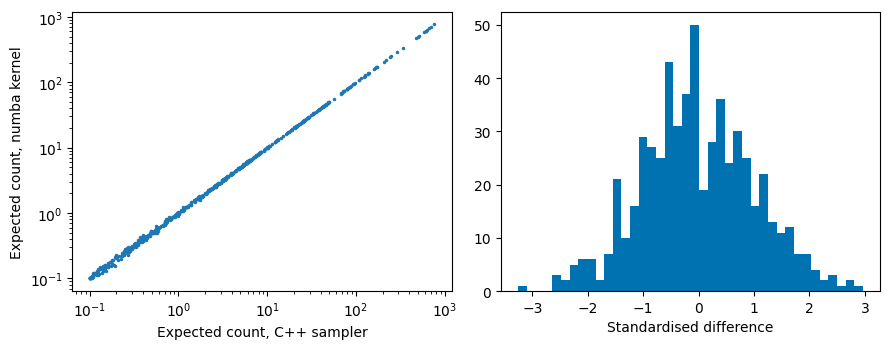

In [7]:
CPP = r"""
#include <random>
#include <cstdint>
#include <vector>
#include <cmath>
extern "C" {
int asc(int* A,int row){int prev=0;for(int k=0;k<6;k++){int v=A[row*6+k];if(v){if(v<=prev)return 0;prev=v;}}return 1;}
void run(int* A,int n,int* er,int* es,int* gid,int* ptr,int ne,int ng,int* qt,int nq,int reps,uint64_t seed,int ordered,int64_t* counts,int64_t* qcounts,double* diag){
 std::mt19937_64 rng(seed); std::vector<int> initial(A,A+n*6);
 std::vector<int> initasc(n);for(int i=0;i<n;i++)initasc[i]=asc(A,i);
 int pm[36][36];int z=0;for(int i=1;i<36;i++)for(int j=i+1;j<36;j++)pm[i][j]=pm[j][i]=z++;
 int64_t accepted=0,proposed=0,changedorder=0;
 for(int b=-1;b<reps;b++){
  int64_t steps=(int64_t)ne*(b<0?20:5);
  for(int64_t t=0;t<steps;t++){
   proposed++;int e=rng()%ne;int g=gid[e];int f=ptr[g]+rng()%(ptr[g+1]-ptr[g]);
   int r=er[e],s=er[f],p=es[e],q=es[f];int v=A[r*6+p],w=A[s*6+q];
   if(r==s||v==w)continue;bool bad=false;
   for(int k=0;k<6;k++)if(A[r*6+k]==w||A[s*6+k]==v){bad=true;break;}
   if(bad)continue;int ar=asc(A,r),as=asc(A,s);
   A[r*6+p]=w;A[s*6+q]=v;
   int br=asc(A,r),bs=asc(A,s);
   if(ordered&&(ar!=br||as!=bs)){A[r*6+p]=v;A[s*6+q]=w;continue;}
   accepted++;if(ar!=br||as!=bs)changedorder++;
  }
  if(b>=0){
   for(int r=0;r<n;r++)for(int p=0;p<6;p++){int v=A[r*6+p];if(!v)continue;
    for(int q=p+1;q<6;q++){int w=A[r*6+q];if(w){int h=pm[v][w];counts[b*595+h]++;qcounts[(b*nq+qt[r])*595+h]++;}}
   }
  }
 }
 int changed=0,changedasc=0,multi=0;for(int i=0;i<n*6;i++)if(A[i]!=initial[i])changed++;
 for(int i=0;i<n;i++){int k=0;for(int j=0;j<6;j++)k+=A[i*6+j]>0;if(k>=2){multi++;changedasc+=asc(A,i)!=initasc[i];}}
 diag[0]=proposed;diag[1]=accepted;diag[2]=(double)accepted/proposed;diag[3]=(double)changed/ne;
 diag[4]=(double)changedasc/(multi?multi:1);diag[5]=(double)changedorder/(accepted?accepted:1);
}
}
"""
cxx = shutil.which("g++") or shutil.which("clang++")
if cxx is None:
    print("No C++ compiler found: cross-check skipped.")
else:
    tmp = Path(tempfile.mkdtemp())
    (tmp / "k.cpp").write_text(CPP)
    subprocess.run(
        [cxx, "-std=c++17", "-O3", "-shared", "-fPIC", str(tmp / "k.cpp"), "-o", str(tmp / "k.so")],
        check=True,
    )
    lib = ctypes.CDLL(str(tmp / "k.so"))
    I = np.ctypeslib.ndpointer(dtype=np.int32, flags="C_CONTIGUOUS")
    L = np.ctypeslib.ndpointer(dtype=np.int64, flags="C_CONTIGUOUS")
    D = np.ctypeslib.ndpointer(dtype=np.float64, flags="C_CONTIGUOUS")
    lib.run.argtypes = [
        I,
        ctypes.c_int,
        I,
        I,
        I,
        I,
        ctypes.c_int,
        ctypes.c_int,
        I,
        ctypes.c_int,
        ctypes.c_int,
        ctypes.c_uint64,
        ctypes.c_int,
        L,
        L,
        D,
    ]
    a, A0, keys = spec_sample("N1")
    win = a.year.between(2008, 2018).to_numpy()
    a = a[win].reset_index(drop=True)
    A0 = A0[win]
    keys = [k for k, w in zip(keys, win) if w]
    er, es, gid, ptr = build_cells(A0, keys)
    reps = 999
    cpp_counts = np.zeros((reps, 595), np.int64)
    qc = np.zeros((reps, 1, 595), np.int64)
    dg = np.zeros(6)
    Ac = np.ascontiguousarray(A0.astype(np.int32))
    lib.run(
        Ac,
        len(Ac),
        er.astype(np.int32),
        es.astype(np.int32),
        gid.astype(np.int32),
        ptr.astype(np.int32),
        len(er),
        len(ptr) - 1,
        np.zeros(len(Ac), np.int32),
        1,
        reps,
        20261199,
        0,
        cpp_counts,
        qc,
        dg,
    )
    z = np.load(AGG / "null_N1.npz")
    nb_counts = z["counts"][:, :11, :].sum(1)  # 2008-2018 from the full-period numba chains
    m1, m2 = cpp_counts.mean(0), nb_counts.mean(0)
    se = np.sqrt(cpp_counts.var(0, ddof=1) / reps + nb_counts.var(0, ddof=1) / reps)
    ok = se > 0
    zdiff = (m1[ok] - m2[ok]) / se[ok]
    xcheck = {
        "pairs_compared": int(ok.sum()),
        "corr_expected": float(np.corrcoef(m1, m2)[0, 1]),
        "mean_z": float(zdiff.mean()),
        "sd_z": float(zdiff.std()),
        "share_abs_z_gt_1.96": float((np.abs(zdiff) > 1.96).mean()),
        "max_abs_z": float(np.abs(zdiff).max()),
        "cpp_acceptance": dg[2],
    }
    display(xcheck)
    (ROOT / "results" / "02_kernel_crosscheck.json").write_text(json.dumps(xcheck, indent=1) + "\n")
    shutil.rmtree(tmp)
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
    ax[0].loglog(m1 + 0.1, m2 + 0.1, ".", ms=3)
    ax[0].set_xlabel("Expected count, C++ sampler")
    ax[0].set_ylabel("Expected count, numba kernel")
    ax[1].hist(zdiff, bins=40, color="#0072B2")
    ax[1].set_xlabel("Standardised difference")
    fig.tight_layout()
    display_figure(fig, "independent_kernel_crosscheck")
